# Compare the port with saved values of the original codes

The 3pcf C code of this project is a port of fastnc (Sugiyama and Heringer
Gomes) and of the Y3 aperture integrator (Gomes et al., arXiv:2601.09133).
The project never runs those codes: their outputs were computed once, at
pinned commits, and saved as JSON fixtures in `tests/`. This notebook
evaluates the port on the same inputs and compares it with the saved
values.

| Section | What it compares |
| --- | --- |
| Saved matter and IA bispectra | the Python BiHalofit theory and the native IA terms against `tests/data_vector/reference_physics_fastnc.json` |
| Matching IA conventions | the amplitude conversion between an upstream $C_1\rho_\mathrm{crit}$ and pivot and CosmoLike's |
| Archived pixel window | the Map3 rows of the joint likelihood with and without the archived HEALPix window |

The unit tests repeat the same fixture comparisons with tolerances
(`tests/data_vector/test_physics_model.py`, `test_aperture.py`,
`test_physics_squeezed.py`). None of this establishes a DES likelihood
reproduction: the original CosmoSIS analysis and the TreeCorr catalogue
measurement are outside this notebook.

In [1]:
import json
import os
from pathlib import Path
import importlib
import sys

# Set these before importing NumPy or a compiled numerical library.
for variable in ("OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "BLIS_NUM_THREADS",
                 "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS", "GOTO_NUM_THREADS"):
    os.environ[variable] = "1"
os.environ["OMP_NUM_THREADS"] = "1"

project = Path.cwd().resolve()
if not (project / "interface").is_dir():
    raise FileNotFoundError("Start this notebook with des_3pcf as its working directory.")
external = project.parents[1] / "external_modules" / "code"

# interface/ holds the compiled library; the cosmolike core holds the
# Python BiHalofit theory and the plotting helpers.
sys.path.insert(0, str(project / "interface"))
sys.path.insert(0, str(external / "cosmolike_core"))

import numpy as np
import cosmolike_des_3pcf_interface as ci
from theory.bihalofit.variance import reference_physics_model, reference_bihalofit
plots = importlib.import_module("cosmolike_notebook_utils.3pcf")

import matplotlib
%matplotlib inline
%config InlineBackend.figure_format = 'retina'
matplotlib.rcParams['mathtext.fontset'] = 'stix'
matplotlib.rcParams['font.family'] = 'STIXGeneral'
matplotlib.rcParams['xtick.bottom'] = True
matplotlib.rcParams['xtick.top'] = False
matplotlib.rcParams['ytick.right'] = False
matplotlib.rcParams['axes.edgecolor'] = 'black'
matplotlib.rcParams['axes.linewidth'] = '1.0'
matplotlib.rcParams['axes.labelsize'] = 'medium'
matplotlib.rcParams['axes.grid'] = True
matplotlib.rcParams['grid.linewidth'] = '0.0'
matplotlib.rcParams['grid.alpha'] = '0.18'
matplotlib.rcParams['grid.color'] = 'lightgray'
matplotlib.rcParams['legend.labelspacing'] = 0.77
matplotlib.rcParams['savefig.bbox'] = 'tight'
matplotlib.rcParams['savefig.format'] = 'pdf'
matplotlib.rcParams['figure.dpi'] = 80

## Saved matter and IA bispectra

The fixture stores the original Python calculation's outputs at six declared
triangles: the four matter-bispectrum components (total, tree, one-halo,
three-halo) and the 19 intrinsic-alignment terms for both settings of
the IA power-spectrum prescription (`power_mode` 0 and 1).
The cell below rebuilds the fixture's smooth input tables, evaluates the
port on the same triangles and reports the largest scaled difference
$\max|x_\mathrm{port}-x_\mathrm{saved}|/\max|x_\mathrm{saved}|$ of each
array.

The original nonlinear-radius root stops at a finite tolerance, so the
matter comparison has an established allowance of $2\times10^{-4}$; the unit
tests check the analytic tree limit and squeezed triangles separately, at
high precision.

In [2]:
# The fixture's input tables: smooth h-unit spectra, a flat background and
# two source curves (the same definition as tests/data_vector/test_physics_model.py).
k = np.geomspace(start=1.0e-5, stop=1.0e3, num=96)
z = np.linspace(start=0.0, stop=2.0, num=41)
linear = 2.0e4 * k / (1.0 + (k / 0.15)**2)**1.8
nonlinear0 = linear * (1.0 + (k / 0.35)**2)**0.22
sources = np.empty(shape=(2, z.size), dtype=np.float64)
sources[0] = z**2 * np.exp(-(z / 0.6)**1.5)
sources[1] = z**2 * np.exp(-(z / 0.95)**1.5)
inputs = dict(
    k=k, p_linear0=linear, z=z,
    p_nonlinear=nonlinear0[None, :] / (1 + z[:, None])**2.4,
    chi=3000 * z / (1 + 0.35 * z),
    dz_dchi=(1 + 0.35 * z)**2 / 3000,
    growth=1 / (1 + z), sources=sources,
    omega_m=0.3, omega_de=0.7, w0=-1.0, wa=0.0,
    ns=0.965, sigma8=0.8,
    los_z=np.linspace(start=0.005, stop=2.0, num=25),
    kernel_nz=101, source_readers=True, table_boost=8,
)

# The saved values and their triangles.
record = json.loads((project / "tests/data_vector/reference_physics_fastnc.json").read_text())
sides = np.asarray(record["sides"], dtype=np.float64)
redshift = np.asarray(record["redshifts"], dtype=np.float64)
print("Saved at fastnc commit", record["source_commit"])

# Matter: the four BiHalofit components of the Python theory.
theory = reference_bihalofit(inputs=inputs)
matter = []
for component in range(4):
    matter.append(theory.evaluate(k1=sides[:, 0], k2=sides[:, 1], k3=sides[:, 2],
                                  z=redshift, component=component))
matter = np.asarray(matter)
saved_matter = np.asarray(record["matter"])
error = np.max(np.abs(matter - saved_matter)) / np.max(np.abs(saved_matter))
print(f"matter, 4 components: max scaled difference {error:.2e}")

# IA: the 19 native terms, for both power modes; the fixture used c1rho = 0.0134.
model = reference_physics_model(factory=ci.production.PhysicsModel, **inputs)
for mode in (0, 1):
    parameters = dict(record["parameters"], c1rho=0.0134, power_mode=mode)
    actual = model.ia(sides=sides, redshifts=redshift, parameters=parameters)
    saved = np.asarray(record["alignment"][str(mode)])
    error = np.max(np.abs(actual - saved)) / np.max(np.abs(saved))
    print(f"IA power mode {mode}, 19 terms: max scaled difference {error:.2e}")

Saved at fastnc commit 7b2336ce37a909bed51f07f32a2a4f096e71b6ce
matter, 4 components: max scaled difference 6.43e-06
IA power mode 0, 19 terms: max scaled difference 3.81e-15
IA power mode 1, 19 terms: max scaled difference 1.69e-15


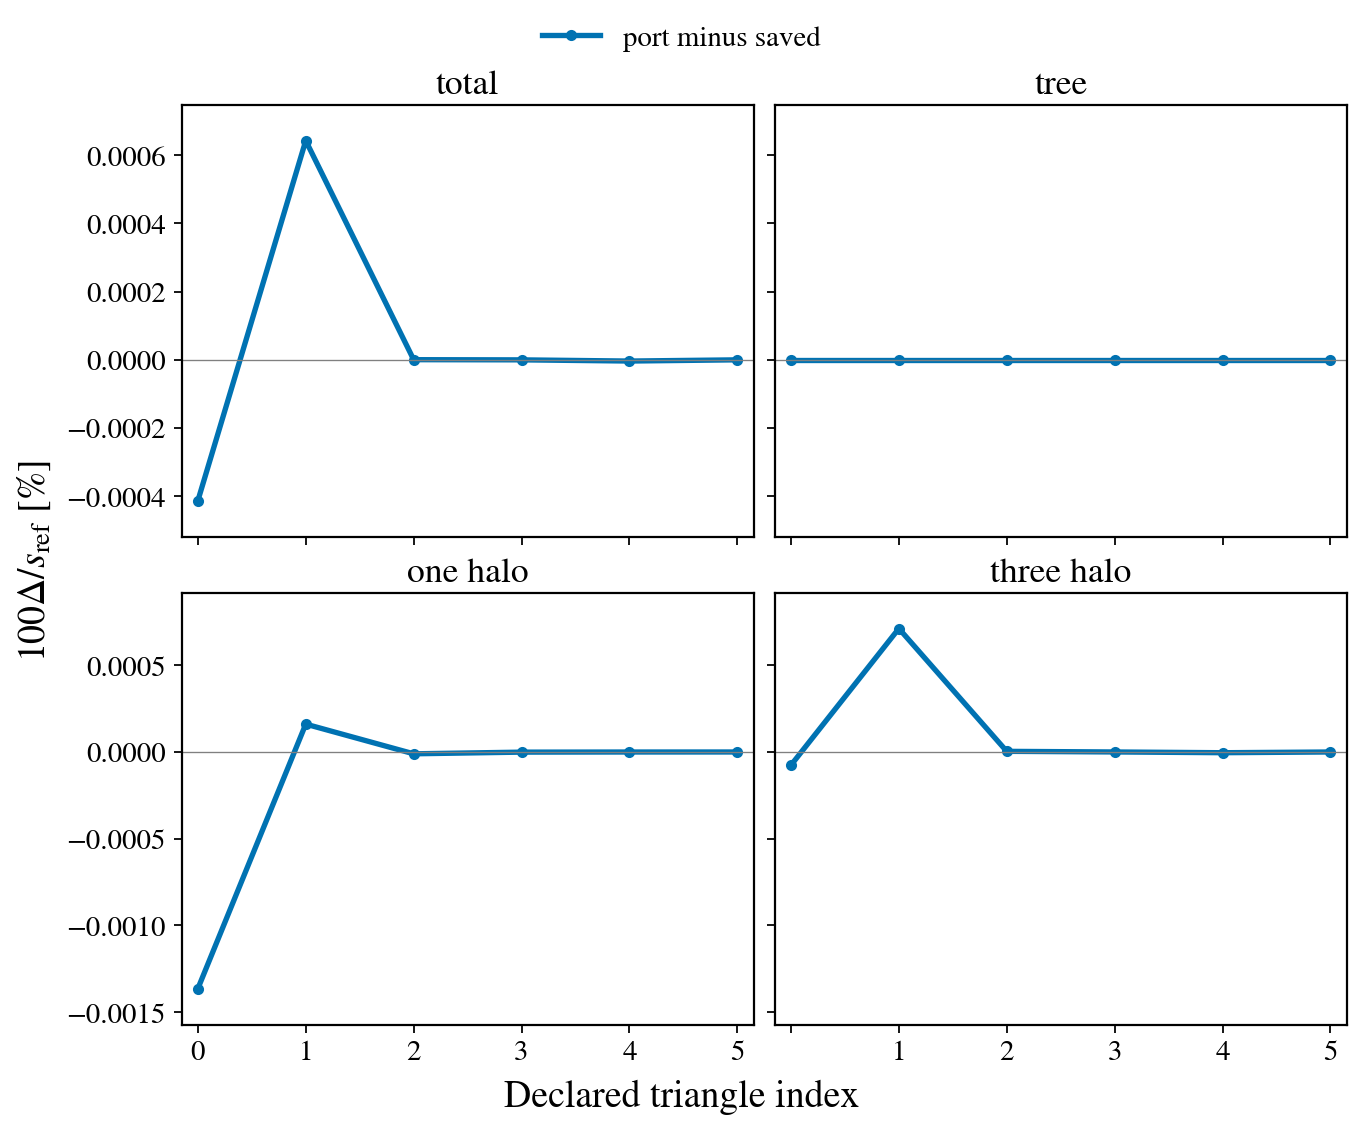

In [3]:
plots.plot_code_comparison(
    x=np.arange(sides.shape[0]), reference=saved_matter, ported=matter,
    labels=["total", "tree", "one halo", "three halo"],
    legend=("port minus saved",), bintextpos=None,
    coordinate_label="Declared triangle index",
    quantity_label="Matter bispectrum [(Mpc/h)^6]",
    residual="scaled", ncols=2, show=1,
)

## Matching intrinsic-alignment conventions

Production uses CosmoLike amplitudes with the normalization
$C_1\rho_{\mathrm{crit}}=0.01389$ and the redshift pivot $z_0=0.62$. An
upstream calculation may instead use $C_1\rho_{\mathrm{crit}}=0.0134$ or
another pivot. For a comparison of the same physical alignment, convert each
amplitude by $(c_{\mathrm{up}}/0.01389)[1.62/(1+z_{\mathrm{up}})]^{\eta}$,
where $c_{\mathrm{up}}$ and $z_{\mathrm{up}}$ are the upstream normalization
and pivot and $\eta$ is that amplitude's redshift slope. The cell below
checks the conversion at double precision. This conversion belongs only to
the comparison; production YAMLs supply CosmoLike amplitudes directly.


In [4]:
upstream_c1rho = 0.0134
upstream_pivot = 0.3
upstream_a1, upstream_eta1 = 0.8, -1.3
upstream_a2, upstream_eta2 = -0.6, 2.1
normalization_ratio = upstream_c1rho / 0.01389
pivot_ratio = 1.62 / (1.0 + upstream_pivot)
cosmolike_a1 = upstream_a1 * normalization_ratio * pivot_ratio**upstream_eta1
cosmolike_a2 = upstream_a2 * normalization_ratio * pivot_ratio**upstream_eta2
z = np.linspace(start=0.0, stop=2.0, num=21)
for amplitude, slope, converted in ((upstream_a1, upstream_eta1, cosmolike_a1),
                                    (upstream_a2, upstream_eta2, cosmolike_a2)):
    upstream = amplitude * upstream_c1rho * ((1.0 + z)/(1.0 + upstream_pivot))**slope
    cocoa = converted * 0.01389 * ((1.0 + z)/1.62)**slope
    np.testing.assert_allclose(actual=cocoa, desired=upstream, rtol=5.e-15)


## The archived pixel-window convention

The archived Y3 theory code (`config/3pt.ini` of the pinned
`3pcf_integrator`) multiplies the bispectrum by a HEALPix pixel window
$W_\ell$ with `nside = 1024`, one factor per leg:
$B^\mathrm{pixel}(\ell_1,\ell_2,\ell_3) = W_{\ell_1}W_{\ell_2}W_{\ell_3}B(\ell_1,\ell_2,\ell_3)$.
This section reproduces that convention and shows its effect on the Map3
rows of the joint likelihood at the `EXAMPLE_EVALUATE3` fiducial.

The convention makes four choices, kept exactly as archived:

| Choice | Value |
| --- | --- |
| Column | the scalar `TEMPERATURE` column of the official HEALPix table |
| Multipoles kept | $\ell = 0, \dots, 3\,n_\mathrm{side}-1 = 3071$, the default length of `healpy.pixwin` |
| Between integer $\ell$ | linear interpolation, done by the C model |
| Above $\ell = 3071$ | $W = 0$: an extra band limit, not part of the pixel window itself |

Scope: this is a reproduction of one archived convention, not a model of
the measurement. The DES Y3 aperture statistic is measured from the shear
catalogue with TreeCorr, so the likelihood applies no pixel window. A
pixel average on a spin-2 shear map is also a different operation from
scalar smoothing. The analytic covariance refuses a smoothed mean, and the
archived radial bank and side offset (recorded in
`tests/studies/estimator_conventions.md`) are not reproduced here.

In [5]:
# Read the HEALPix scalar window and check it against its manifest
# (data/pixel_window_manifest.yaml: source commit, sha256, nside, ell_max).
import hashlib

import numpy as np
import yaml
from astropy.io import fits

manifest = yaml.safe_load((project / "data/pixel_window_manifest.yaml").read_text())
window_file = project / "data" / manifest["path"]
nside = manifest["nside"]

if manifest["sha256"] != hashlib.sha256(window_file.read_bytes()).hexdigest():
    raise ValueError(f"{window_file} differs from its manifest; restore the file.")
if 3 * nside - 1 != manifest["ell_max"]:
    raise ValueError("The manifest's ell_max is not 3*nside - 1.")

with fits.open(window_file, memmap=False) as hdus:
    table = hdus[1]
    if nside != table.header["NSIDE"] or "TEMPERATURE" not in table.columns.names:
        raise ValueError("The FITS table is not the scalar window for this nside.")
    # Keep ell = 0..3*nside-1; the C model reads zero above the last sample.
    window = np.array(table.data["TEMPERATURE"][:3 * nside], dtype=np.float64)

print(f"W at ell = 0, 1024, 3071: {window[0]:.6f}, {window[1024]:.6f}, {window[-1]:.6f}")

W at ell = 0, 1024, 3071: 1.000000, 0.954245, 0.646451


In [6]:
# Evaluate the Cobaya likelihood once at the EXAMPLE_EVALUATE3 fiducial.
from cobaya.model import get_model
from cobaya.yaml import yaml_load_file
import cosmolike_des_3pcf_interface as ci

info = yaml_load_file(str(project / "EXAMPLE_EVALUATE3.yaml"))
fiducial = dict(info["sampler"]["evaluate"]["override"])
info.pop("sampler")
info.pop("output")
info["theory"]["camb"]["path"] = str(external / "CAMB")
model = get_model(info_or_yaml_or_file=info)
model.logposterior(params_values=fiducial, cached=False)
likelihood = model.likelihood["des_3pcf.joint_shear"]


def map3_model(pixel_window):
    # The likelihood's own constructor call (set_source_related), with the
    # same arrays and counts, plus the optional window.
    normalization = likelihood.baseline.get("metadata", {}).get(
        "linear_power_normalization", 1.0)
    counts = ci.accuracy_model_settings(
        accuracy=likelihood.accuracy, kernel_nz=likelihood.kernel_nz,
        table_boost=likelihood.table_boost, fit_nz=likelihood.fit_nz)
    return ci.production.PhysicsModelWithBispectrum(
        k=10.0**likelihood.log10k_interp_2D,
        p_linear0=likelihood.p_linear[0] * normalization,
        z=likelihood.z_interp_2D,
        p_nonlinear=likelihood.p_nonlinear,
        chi=likelihood.chi,
        dz_dchi=likelihood.dz_dchi,
        growth=likelihood.growth,
        sources=likelihood.sources,
        source_z=likelihood.source_z,
        los_z=likelihood.los_z,
        omega_m=float(likelihood.omega_m_z[0]),
        omega_m_z=likelihood.omega_m_z,
        sigma8=likelihood.sigma8,
        baseline=likelihood.baseline["native"],
        kernel_nz=counts["kernel_nz"],
        table_boost=counts["table_boost"],
        fit_nz=counts["fit_nz"],
        source_readers=False,
        feedback=likelihood.feedback,
        pixel_window=pixel_window,
    )


def map3_rows(physics):
    return likelihood.map_engine.aperture_vector(
        model=physics, ia=likelihood.ia, calibration=likelihood.calibration)


# The rebuilt unsmoothed model must give the likelihood's Map3 rows exactly;
# this checks that the copied constructor call is the likelihood's.
plain = map3_rows(physics=map3_model(pixel_window=None))
scored = likelihood.last_datavector[likelihood.map_indices]
np.testing.assert_array_equal(plain.view(np.uint64), scored.view(np.uint64))

smoothed = map3_rows(physics=map3_model(pixel_window=window))
change = 100.0 * (smoothed / plain - 1.0)
print(f"Map3 rows: {plain.size}; window change from {change.min():.3f}% to {change.max():.3f}%")

[camb] `camb` module loaded successfully from /Users/vivianmiranda/data/COCOA/november2026/sbu_cosmolike/cocoa/Cocoa/external_modules/code/CAMB/camb


Map3 rows: 80; window change from -6.839% to -0.330%


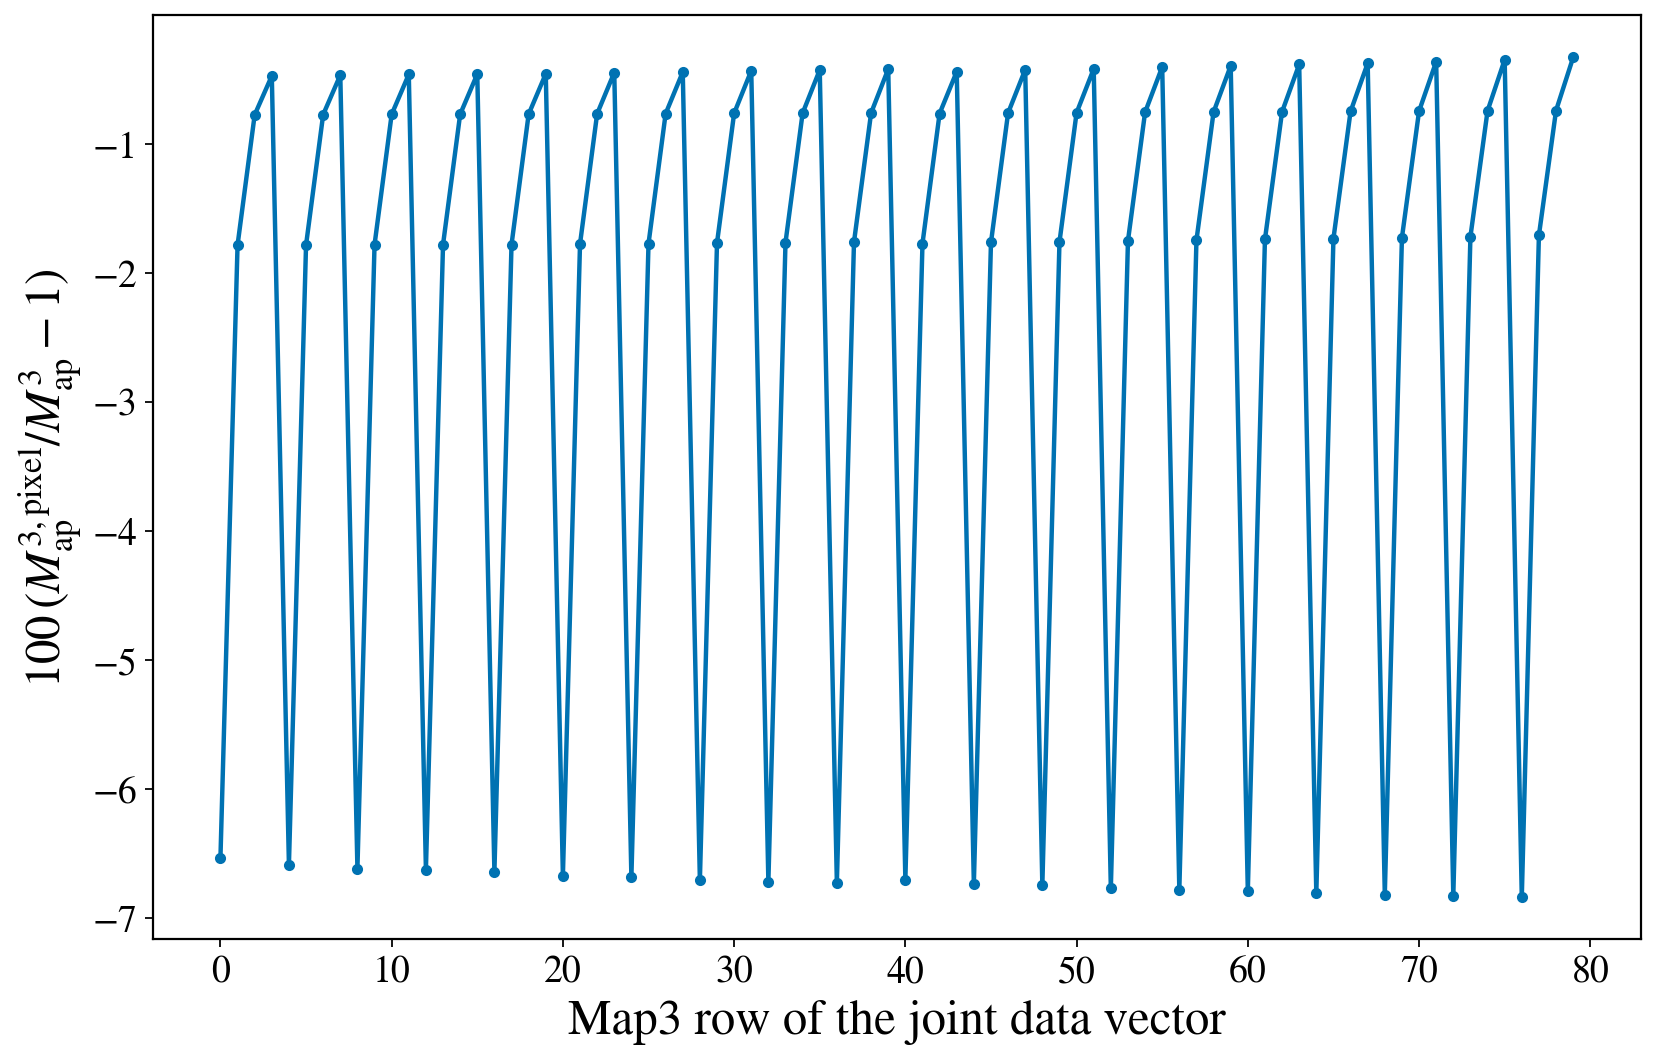

In [7]:
from matplotlib import pyplot as plt

figure, axis = plt.subplots(figsize=(12, 7.5))
axis.plot(np.arange(change.size), change, color="#0072B2", linewidth=2.0,
          marker="o", markersize=4)
axis.set_xlabel("Map3 row of the joint data vector", fontsize=22)
axis.set_ylabel(r"$100\,(M_\mathrm{ap}^{3,\mathrm{pixel}}/M_\mathrm{ap}^3 - 1)$", fontsize=22)
axis.tick_params(labelsize=17)
plt.show()

## What the result establishes

The comparisons check the port against saved outputs of the original
codes on fixed inputs, and show the size of the archived pixel window on
the Map3 rows. They do not check a catalogue measurement, the original
CosmoSIS likelihood, survey masks or grid convergence.

Credits: fastnc is by Sunao Sugiyama and Rafael Heringer Gomes, and the
aperture routine adapts Mike Jarvis's TreeCorr implementation (Gomes et al.,
arXiv:2601.09133). Each JSON fixture records the commit it was computed at.